# Exploratory Data Analysis (EDA) — Complete Revision Notebook
### Lectures 77–96 | Concepts, practical code, exercises, and challenging questions

**Goal:** practise the EDA workflow used before Machine Learning: inspect, clean, explore, visualize, investigate relationships, check data quality, and prepare data safely for modelling.

**How to use this notebook**
1. Run the cells from top to bottom.
2. Read the comments and compare your output with the questions.
3. Attempt the practice questions before opening the solutions.
4. The dataset is synthetic and for learning only; its patterns are not real-world evidence.

## 1. EDA workflow

1. Load the data.
2. Inspect shape, columns, types, and sample rows.
3. Check missing values, duplicates, invalid values, and inconsistent categories.
4. Summarize numerical and categorical columns.
5. Explore individual features (univariate analysis).
6. Explore relationships (bivariate and multivariate analysis).
7. Investigate outliers and the target variable.
8. Check leakage, bias, and split strategy.
9. Document findings and prepare a reproducible ML pipeline.

**Remember:** EDA describes and investigates data. It does not automatically prove causes or guarantee a good model.

## 2. Imports and create a practice dataset

This dataset intentionally includes a few missing values, an extreme but potentially valid salary, and a duplicate record. We will inspect these before deciding what to do.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
sns.set_theme()

df = pd.DataFrame({
    "Employee_ID": range(101, 116),
    "Age": [22, 25, 28, 30, 35, 40, 45, 50, 29, 32, 35, 25, 31, 42, 38],
    "Experience": [0, 2, 4, 6, 10, 15, 20, 25, 5, 7, 10, 2, 6, 18, 12],
    "Education": [
        "Graduate", "Graduate", "Masters", "Graduate", "Masters",
        "Masters", "PhD", "PhD", "Masters", "Graduate", "Masters",
        "Graduate", "Graduate", "PhD", "Masters"
    ],
    "Department": [
        "IT", "HR", "IT", "Finance", "IT", "Finance", "IT", "Finance",
        "HR", "IT", "Finance", "HR", "Finance", "IT", "HR"
    ],
    "Salary": [
        25000, 30000, 40000, 45000, 60000, 80000, 100000, 120000,
        42000, 50000, 65000, 32000, np.nan, 110000, 58000
    ],
    "Performance_Score": [3, 3, 4, 3, 4, 4, 5, 5, 3, 4, 4, 3, 3, 5, np.nan]
})

# Add one exact duplicate row for practice.
df = pd.concat([df, df.iloc[[0]]], ignore_index=True)

df.head()

,Employee_ID,Age,Experience,Education,Department,Salary,Performance_Score
0,101,22,0,Graduate,IT,25000.0,3.0
1,102,25,2,Graduate,HR,30000.0,3.0
2,103,28,4,Masters,IT,40000.0,4.0
3,104,30,6,Graduate,Finance,45000.0,3.0
4,105,35,10,Masters,IT,60000.0,4.0


## 3. Inspect the dataset

Key tools:
- `shape`: number of rows and columns
- `head()` / `tail()`: inspect sample rows
- `info()`: data types and non-null counts
- `dtypes`: type of each column
- `describe()`: numerical summary
- `describe(include="all")`: summary including categories

In [2]:
print("Shape:", df.shape)
print("\nColumns:", df.columns.tolist())
print("\nData types:\n", df.dtypes)
print("\nDataset info:")
df.info()
print("\nNumerical summary:\n", df.describe())
print("\nAll-column summary:\n", df.describe(include="all"))

Shape: (16, 7)

Columns: ['Employee_ID', 'Age', 'Experience', 'Education', 'Department', 'Salary', 'Performance_Score']

Data types:
 Employee_ID            int64
Age                    int64
Experience             int64
Education                str
Department               str
Salary               float64
Performance_Score    float64
dtype: object

Dataset info:
<class 'pandas.DataFrame'>
RangeIndex: 16 entries, 0 to 15
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Employee_ID        16 non-null     int64  
 1   Age                16 non-null     int64  
 2   Experience         16 non-null     int64  
 3   Education          16 non-null     str    
 4   Department         16 non-null     str    
 5   Salary             15 non-null     float64
 6   Performance_Score  15 non-null     float64
dtypes: float64(2), int64(3), str(2)
memory usage: 1.2 KB

Numerical summary:
        Employee_ID      Age  Exp

## 4. Missing values

Count missing values and calculate percentages. A missing target value is different from a missing input feature: in supervised learning, rows with unknown targets are often excluded from training rather than filling the target with a guessed value.

In [3]:
missing_count = df.isna().sum()
missing_percent = (df.isna().mean() * 100).round(2)

missing_summary = pd.DataFrame({
    "missing_count": missing_count,
    "missing_percent": missing_percent
})
missing_summary

,missing_count,missing_percent
Employee_ID,0,0.00
Age,0,0.00
Experience,0,0.00
Education,0,0.00
Department,0,0.00
Salary,1,6.25
Performance_Score,1,6.25


### Missing-value decisions

- Investigate why values are missing and whether missingness has a pattern.
- Numerical input: median imputation is a common baseline.
- Categorical input: most-frequent or an explicit `Unknown` category may be reasonable.
- Unknown target: usually do not invent a target value for supervised training.
- Fit imputers on training data only, preferably inside a scikit-learn pipeline.

## 5. Duplicate rows and data quality

An identical row is not always an error in real data. Check the domain and whether a unique identifier should distinguish records before removing duplicates.

In [4]:
print("Exact duplicate rows:", df.duplicated().sum())
print("Duplicate rows (shown):")
display(df[df.duplicated(keep=False)].sort_values("Employee_ID"))

# For this synthetic exercise, we know the appended row is accidental.
df_clean = df.drop_duplicates().copy()
print("Shape before:", df.shape)
print("Shape after:", df_clean.shape)
print("Duplicates remaining:", df_clean.duplicated().sum())

Exact duplicate rows: 1
Duplicate rows (shown):


,Employee_ID,Age,Experience,Education,Department,Salary,Performance_Score
0,101,22,0,Graduate,IT,25000.0,3.0
15,101,22,0,Graduate,IT,25000.0,3.0


Shape before: (16, 7)
Shape after: (15, 7)
Duplicates remaining: 0


### Check validity and consistency

A data-quality check should reflect domain rules. For this example, negative age, experience, or salary is suspicious; experience greater than age deserves investigation. Do not assume every flagged record is wrong without checking the context.

In [5]:
print("Negative age:", (df_clean["Age"] < 0).sum())
print("Negative experience:", (df_clean["Experience"] < 0).sum())
print("Non-positive salary:", (df_clean["Salary"] <= 0).sum())
print("Experience greater than age:")
display(df_clean[df_clean["Experience"] > df_clean["Age"]])

# Standardize category text only after checking that variants mean the same thing.
for col in ["Education", "Department"]:
    print(f"\n{col} unique values:", df_clean[col].dropna().unique())

Negative age: 0
Negative experience: 0
Non-positive salary: 0
Experience greater than age:


,Employee_ID,Age,Experience,Education,Department,Salary,Performance_Score



Education unique values: <ArrowStringArray>
['Graduate', 'Masters', 'PhD']
Length: 3, dtype: str

Department unique values: <ArrowStringArray>
['IT', 'HR', 'Finance']
Length: 3, dtype: str


## 6. Descriptive statistics and grouped summaries

In [6]:
print(df_clean[["Age", "Experience", "Salary", "Performance_Score"]].describe())

print("Salary mean:", df_clean["Salary"].mean())
print("Salary median:", df_clean["Salary"].median())

department_summary = (
    df_clean.groupby("Department")["Salary"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(2)
)
department_summary

             Age  Experience         Salary  Performance_Score
count  15.000000   15.000000      14.000000          14.000000
mean   33.800000    9.466667   61214.285714           3.785714
std     7.974961    7.288608   30466.068317           0.801784
min    22.000000    0.000000   25000.000000           3.000000
25%    28.500000    4.500000   40500.000000           3.000000
50%    32.000000    7.000000   54000.000000           4.000000
75%    39.000000   13.500000   76250.000000           4.000000
max    50.000000   25.000000  120000.000000           5.000000
Salary mean: 61214.28571428572
Salary median: 54000.0


,count,mean,median,min,max
Department,,,,,
Finance,4,77500.00,72500.0,45000.0,120000.0
HR,4,40500.00,37000.0,30000.0,58000.0
IT,6,64166.67,55000.0,25000.0,110000.0


## 7. Univariate analysis

Univariate analysis studies one feature at a time.

- Histogram: numerical distribution
- Box plot: median, quartiles, spread, and potential outliers
- Count plot / `value_counts()`: category frequencies

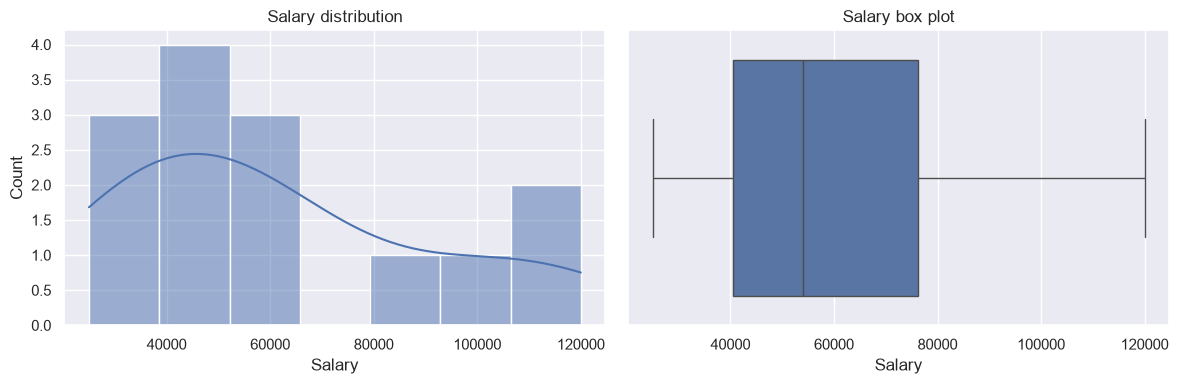

Department
IT         6
Finance    5
HR         4
Name: count, dtype: int64
Education
Graduate    6
Masters     6
PhD         3
Name: count, dtype: int64


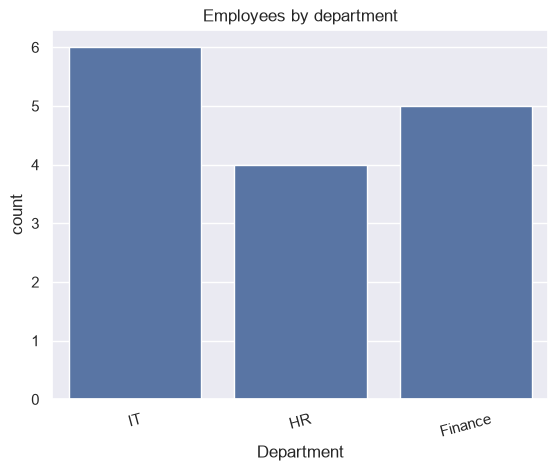

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(data=df_clean, x="Salary", bins=7, kde=True, ax=axes[0])
axes[0].set_title("Salary distribution")

sns.boxplot(data=df_clean, x="Salary", ax=axes[1])
axes[1].set_title("Salary box plot")

plt.tight_layout()
plt.show()

print(df_clean["Department"].value_counts(dropna=False))
print(df_clean["Education"].value_counts(dropna=False))

sns.countplot(data=df_clean, x="Department")
plt.title("Employees by department")
plt.xticks(rotation=15)
plt.show()

## 8. Bivariate analysis

Bivariate analysis investigates two variables. Use domain knowledge to interpret the chart and avoid treating association as proof of cause.

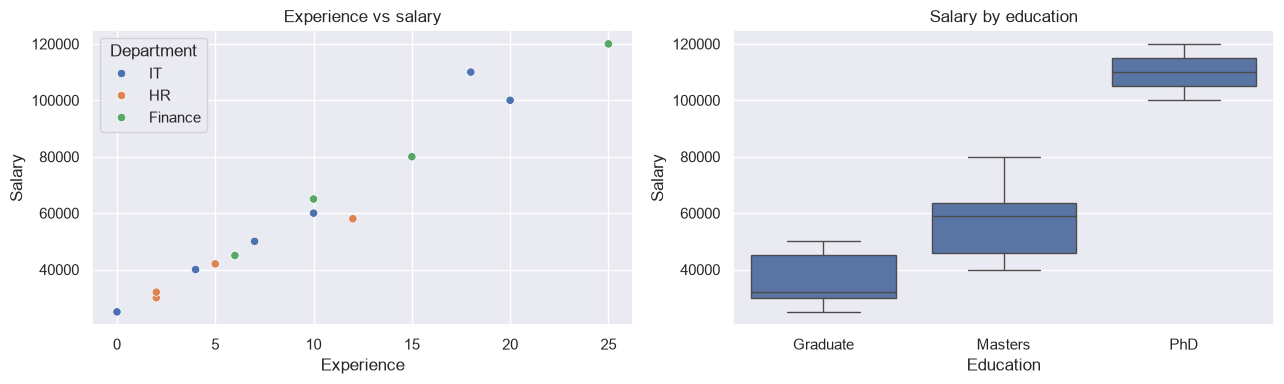

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.scatterplot(
    data=df_clean, x="Experience", y="Salary",
    hue="Department", ax=axes[0]
)
axes[0].set_title("Experience vs salary")

sns.boxplot(
    data=df_clean, x="Education", y="Salary", ax=axes[1]
)
axes[1].set_title("Salary by education")
plt.tight_layout()
plt.show()

## 9. Multivariate analysis and correlation

Pearson correlation measures linear association and ranges from -1 to +1. A near-zero Pearson correlation does not rule out a nonlinear relationship. Correlation does not prove causation, and outliers can influence it.

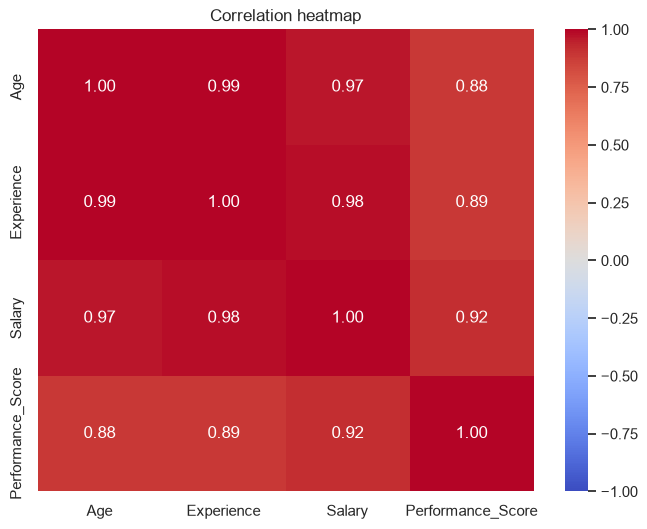

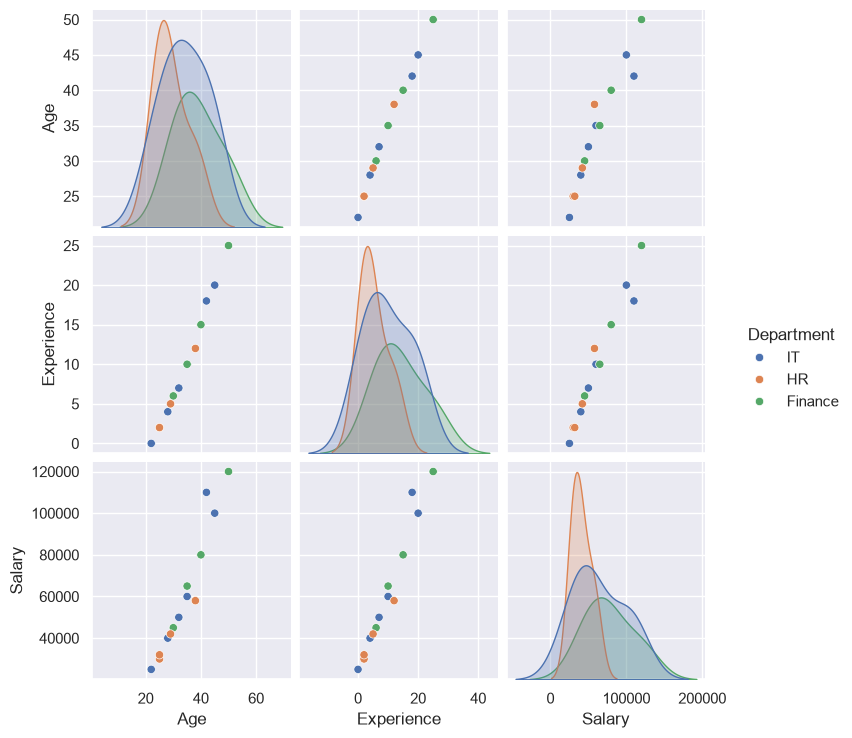

In [9]:
numeric = df_clean.select_dtypes(include="number").drop(columns=["Employee_ID"], errors="ignore")
corr = numeric.corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt=".2f")
plt.title("Correlation heatmap")
plt.show()

# Pair plot can be useful on a small number of features.
sns.pairplot(
    df_clean[["Age", "Experience", "Salary", "Department"]].dropna(),
    hue="Department"
)
plt.show()

## 10. Outlier investigation with IQR and Z-scores

The IQR rule flags observations below `Q1 - 1.5*IQR` or above `Q3 + 1.5*IQR`. This is a flag for investigation, not proof of bad data.

Z-scores describe how many standard deviations a value is from the mean. Z-scores can be strongly affected by outliers and are most straightforward to interpret for approximately normal data.

In [10]:
salary = df_clean["Salary"].dropna()

q1 = salary.quantile(0.25)
q3 = salary.quantile(0.75)
iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

iqr_flags = df_clean[(df_clean["Salary"] < lower) | (df_clean["Salary"] > upper)]
print("IQR lower bound:", lower)
print("IQR upper bound:", upper)
display(iqr_flags)

mean_salary = salary.mean()
std_salary = salary.std(ddof=0)
if std_salary != 0:
    z_scores = (salary - mean_salary) / std_salary
    print("Rows with absolute Z-score > 3:")
    display(df_clean.loc[z_scores.index[z_scores.abs() > 3]])

IQR lower bound: -13125.0
IQR upper bound: 129875.0


,Employee_ID,Age,Experience,Education,Department,Salary,Performance_Score


Rows with absolute Z-score > 3:


,Employee_ID,Age,Experience,Education,Department,Salary,Performance_Score


## 11. Target analysis and class imbalance

Our current target `Salary` is numeric, so this is a **regression** problem. For a classification target, inspect class counts and proportions. Accuracy can be misleading when one class dominates.

Example: if 990 cases are legitimate and 10 are fraud, predicting every case as legitimate gives 99% accuracy but detects zero fraud cases.

In [11]:
# Regression target summary
print(df_clean["Salary"].describe())

# Classification example: counts and proportions for a hypothetical target
example_labels = pd.Series(["Legitimate"] * 990 + ["Fraud"] * 10, name="Target")
print(example_labels.value_counts())
print((example_labels.value_counts(normalize=True) * 100).round(2))

# For classification, consider precision, recall, F1, and a confusion matrix,
# not accuracy alone.

count        14.000000
mean      61214.285714
std       30466.068317
min       25000.000000
25%       40500.000000
50%       54000.000000
75%       76250.000000
max      120000.000000
Name: Salary, dtype: float64
Target
Legitimate    990
Fraud          10
Name: count, dtype: int64
Target
Legitimate    99.0
Fraud          1.0
Name: proportion, dtype: float64


## 12. Leakage, bias, and safe ML preparation

Common leakage risks:
- Fitting an imputer, scaler, or encoder on the complete dataset before splitting.
- Using a feature that contains future information or is derived from the target.
- Selecting features using the test labels before evaluation.
- Randomly splitting time-dependent observations when future prediction is the goal.
- Allowing the same person, customer, or device to appear in both train and test when that creates overlap.

A pipeline helps prevent preprocessing leakage, but it does not fix target leakage, biased labels, or an unsuitable split strategy.

## 13. End-to-end preprocessing pipeline (regression)

This example drops rows with missing target values, then splits the data. Input missing values are imputed, numerical inputs are scaled, and categorical inputs are one-hot encoded. All learned preprocessing is fitted using the training data through the pipeline.

The sample is deliberately tiny. Treat model metrics as a coding demonstration, not a reliable estimate of real-world performance.

In [12]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Salary must be known for supervised training.
model_df = df_clean.dropna(subset=["Salary"]).copy()

X = model_df[[
    "Age", "Experience", "Education", "Department", "Performance_Score"
]]
y = model_df["Salary"]

numeric_features = ["Age", "Experience", "Performance_Score"]
categorical_features = ["Education", "Department"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

model.fit(X_train, y_train)
predictions = model.predict(X_test)

print("Actual:", y_test.tolist())
print("Predicted:", np.round(predictions, 2).tolist())
print("MAE:", round(mean_absolute_error(y_test, predictions), 2))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, predictions)), 2))
print("R2:", round(r2_score(y_test, predictions), 3))

Actual: [50000.0, 32000.0, 25000.0, 110000.0]
Predicted: [41896.74, 29048.91, 28956.52, 96260.87]
MAE: 7187.5
RMSE: 8348.5
R2: 0.938


## 14. Practice questions — attempt before reading solutions

### Beginner
1. What is the difference between `df.shape` and `df.info()`?
2. Write code to count missing values in every column.
3. Which chart would you use to inspect one numerical variable?
4. What is the difference between a numerical and categorical feature?
5. What does `df.groupby("Department")["Salary"].mean()` calculate?

### Intermediate
6. Write code to calculate the percentage of missing values per column.
7. Find salary outliers using the IQR rule.
8. Create a scatter plot of Experience against Salary, coloured by Department.
9. Explain why correlation does not prove causation.
10. Explain why fitting a scaler before splitting can leak information.

### Challenging / company-style scenarios
11. A dataset has 40% missing income values. What would you investigate before choosing an imputation method?
12. A fraud model has 99% accuracy but detects no fraud cases. Explain why and name better metrics.
13. A feature called `final_claim_amount` is available only after a claim is processed. Should it be used to predict fraud at claim submission time? Explain.
14. Your dataset has multiple records per customer. How could a random row split overestimate performance, and what split could help?
15. A box plot flags a senior employee's unusually high salary. What steps would you take before changing the value?
16. A feature has almost zero Pearson correlation with the target. Does that mean it is useless? Explain.
17. You see a strong correlation between age and experience. What would you investigate before modelling?
18. Your production data contains a city category absent from training. How can your preprocessing handle it safely?

## 15. Answer key and explanations

1. `shape` gives row/column counts; `info()` summarizes columns, types, and non-null counts.
2. `df.isna().sum()`
3. A histogram; a box plot can complement it.
4. Numerical features represent measured/countable quantities; categorical features represent labels or groups.
5. It calculates mean salary for each department.
6. `(df.isna().mean() * 100).round(2)`
7. Calculate Q1, Q3, IQR and flag values outside Q1 − 1.5×IQR and Q3 + 1.5×IQR.
8. `sns.scatterplot(data=df, x="Experience", y="Salary", hue="Department")`
9. Association alone cannot establish cause; confounders, reverse direction, or coincidence may explain a relationship.
10. The scaler learns statistics from the test set. Split first; fit on training data and transform test data using those learned parameters.
11. Investigate why data is missing, missingness patterns, whether missingness is informative, feature distributions, data collection process, and how imputation affects results. Compare sensible strategies using validation.
12. The classes are imbalanced. Check recall, precision, F1, confusion matrix, and potentially precision-recall AUC; choose metrics based on business costs.
13. No, not if that information is unavailable at prediction time. It is a likely leakage feature.
14. Rows from the same customer can appear in both sets, making the test set too similar to training. Consider group-aware splitting such as `GroupKFold` or `GroupShuffleSplit`.
15. Verify the source and business context, compare related records, check units and entry errors, consult domain rules, then retain or correct it based on evidence.
16. No. The relationship may be nonlinear, conditional on other features, or useful through interactions. Examine plots, domain context, and validation-based feature importance.
17. Assess redundancy, multicollinearity, domain meaning, and whether both features improve validation performance; avoid causal conclusions.
18. Use an encoder such as `OneHotEncoder(handle_unknown="ignore")`, fitted on training data and reused in a pipeline.

## 16. Quick-reference cheat sheet

| Goal | Code |
|---|---|
| Dataset dimensions | `df.shape` |
| Data types and null counts | `df.info()` |
| Missing values | `df.isna().sum()` |
| Missing-value percentages | `df.isna().mean() * 100` |
| Duplicate count | `df.duplicated().sum()` |
| Numerical summary | `df.describe()` |
| Category counts | `df["column"].value_counts()` |
| Histogram | `sns.histplot(data=df, x="column")` |
| Box plot | `sns.boxplot(data=df, x="column")` |
| Scatter plot | `sns.scatterplot(data=df, x="x", y="y")` |
| Grouped summary | `df.groupby("group")["target"].agg(["mean", "median", "count"])` |
| Correlation | `df.select_dtypes("number").corr()` |
| Split | `train_test_split(X, y, test_size=0.2, random_state=42)` |

### Final checklist
- [ ] I inspected the shape, columns, and types.
- [ ] I investigated missing values and duplicates.
- [ ] I checked category consistency and domain rules.
- [ ] I examined distributions and relationships.
- [ ] I investigated, rather than automatically deleted, outliers.
- [ ] I checked target quality and possible leakage.
- [ ] I split data before fitting learned preprocessing.
- [ ] I used a pipeline and suitable evaluation metrics.
- [ ] I documented limitations and findings.